In [77]:
import torch as torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from torchvision.transforms import ToTensor
from torchmetrics.classification import Accuracy
from torch import nn
from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import LinearLR, StepLR, ExponentialLR, CosineAnnealingLR, ReduceLROnPlateau, SequentialLR, CosineAnnealingWarmRestarts
from sklearn.datasets import make_classification, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from matplotlib.colors import ListedColormap

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

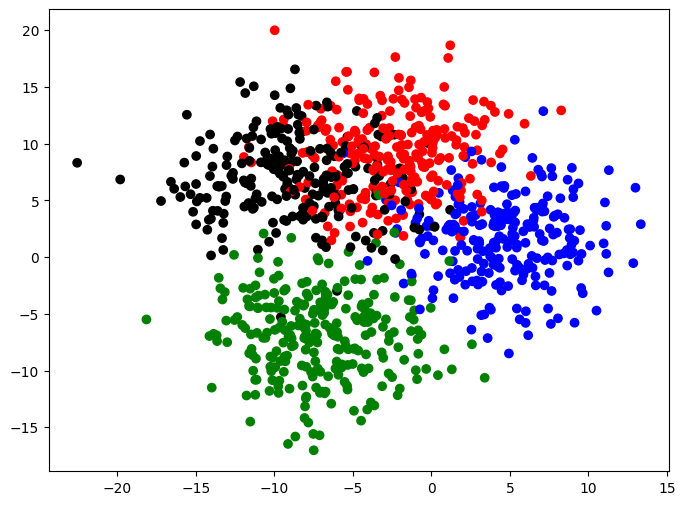

In [47]:
X, y = make_blobs(
    n_samples=5000,
    n_features=2,
    centers=4,
    cluster_std=3.5,
    random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=26)
plt.figure(figsize=(8, 6))
plt.scatter(X_train[0::4, 0], X_train[0::4, 1], c=y_train[0::4], cmap=ListedColormap(['red', 'blue' , 'green', 'black']))
plt.show()

In [31]:
def get_accuracy(model, X, y):
  metric = Accuracy('multiclass', num_classes=4).to(device)
  model.eval()
  with torch.inference_mode():
    y_pred = model(X.to(device))
    metric.update(y_pred, y.to(device))
  return metric.compute().item()

def get_accuracy(model, X, y):
  metric = Accuracy('multiclass', num_classes=4).to(device)
  model.eval()
  with torch.inference_mode():
    y_pred = model(X.to(device))
    metric.update(y_pred, y.to(device))
  return metric.compute().item()

def train_model(model, train_loader, test_loader,
                optimizer, loss_function, epochs):
  train_loss, test_loss = [], []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))
  return train_loss, test_loss



In [32]:
class DropoutModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(2, 64), nn.LeakyReLU(0.05), nn.Dropout(0.5),
        nn.Linear(64, 32), nn.LeakyReLU(0.05), nn.Dropout(0.5),
        nn.Linear(32, 4),
    )
  def forward(self, X):
    return self.model(X)

class SimpleModel(nn.Module):
    def __init__(self):
      super().__init__()
      self.model = nn.Sequential(
          nn.Linear(2, 64), nn.LeakyReLU(0.05), nn.Dropout(0.5),
          nn.Linear(64, 32), nn.LeakyReLU(0.05), nn.Dropout(0.5),
          nn.Linear(32, 4),
      )
    def forward(self, X):
      return self.model(X)

def initialize(m):
  if isinstance(m, nn.Linear):
    nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu', a=0.05)
    nn.init.zeros_(m.bias)

def plot_decision_boundary(model, X, y, title=None):
    cmap = ListedColormap(['red', 'blue', 'orange', 'black'])
    X = torch.as_tensor(X, dtype=torch.float32).cpu()
    y = torch.as_tensor(y).cpu()

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = torch.meshgrid(
        torch.linspace(x_min, x_max, 300),
        torch.linspace(y_min, y_max, 300),
        indexing='xy',
    )
    grid = torch.stack([xx.ravel(), yy.ravel()], dim=1).to(device)
    model.eval()
    with torch.inference_mode():
        pred = model(grid).argmax(1).cpu().reshape(xx.shape)

    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, 4, 1))
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, s=12, edgecolor='k', linewidth=0.3)
    plt.title(title)
    plt.show()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_train = torch.tensor(X_train, dtype=torch.float).to(device)
y_train = torch.LongTensor(y_train).to(device)
X_test = torch.tensor(X_test, dtype=torch.float).to(device)
y_test = torch.LongTensor(y_test).to(device)


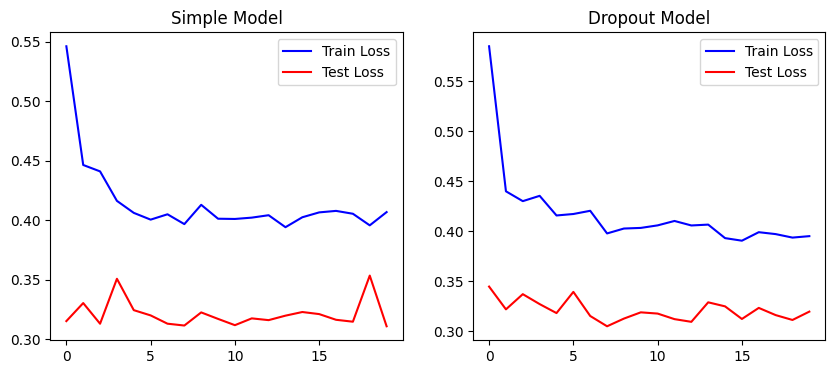

In [33]:
model_1 = SimpleModel().to(device).apply(initialize)
model_2 = DropoutModel().to(device).apply(initialize)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)
loss_function = nn.CrossEntropyLoss()
optimizer_1 = AdamW(model_1.parameters(), lr=0.01, weight_decay=0.01)
optimizer_2 = AdamW(model_2.parameters(), lr=0.01, weight_decay=0.01)
train_loss_1, test_loss_1 = train_model(model_1, train_loader, test_loader, optimizer_1, loss_function, 20)
train_loss_2, test_loss_2 = train_model(model_2, train_loader, test_loader, optimizer_2, loss_function, 20)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(train_loss_1, label='Train Loss', color='blue')
ax[0].plot(test_loss_1, label='Test Loss', color='red')
ax[0].set_title('Simple Model')
ax[0].legend()
ax[1].plot(train_loss_2, label='Train Loss', color='blue')
ax[1].plot(test_loss_2, label='Test Loss', color='red')
ax[1].set_title('Dropout Model')
ax[1].legend()
plt.show()

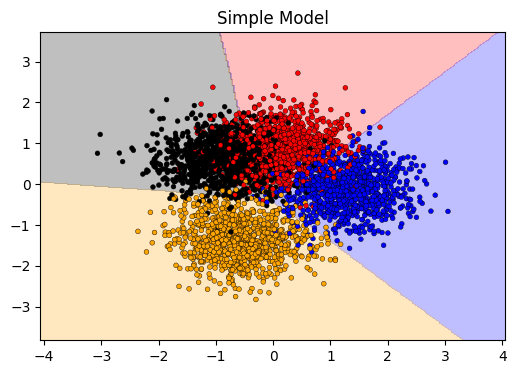

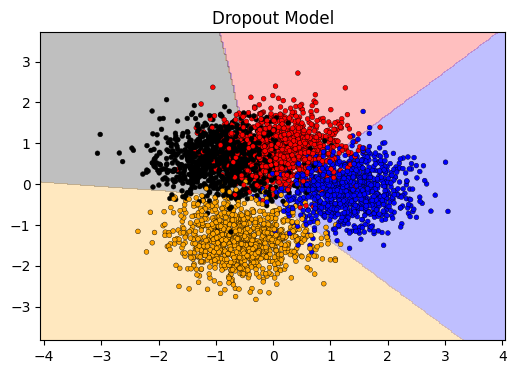

In [34]:
plot_decision_boundary(model_1, X_train, y_train, 'Simple Model')
plot_decision_boundary(model_1, X_train, y_train, 'Dropout Model')



In [36]:
get_accuracy(model_1, X_train, y_train), get_accuracy(model_2, X_test, y_test)

(0.8637499809265137, 0.8659999966621399)

In [45]:
def train_model(model, train_loader, test_loader,
                optimizer, scheduler, loss_function, epochs):
  train_loss, test_loss = [], []
  lr_history = []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
      learning_rate = optimizer.param_groups[0]['lr']
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))
    scheduler.step()
    lr_history.append(learning_rate)
  return train_loss, test_loss, lr_history


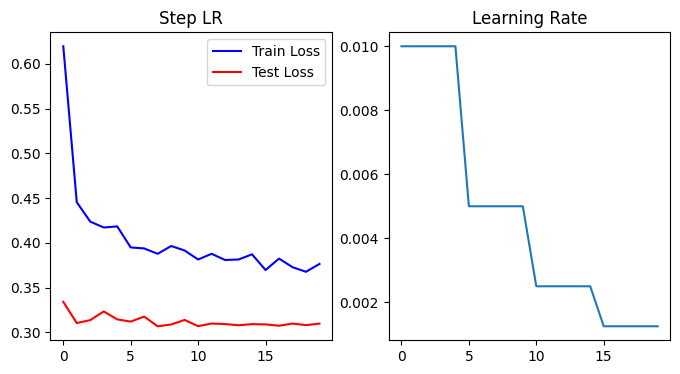

In [53]:
model_3 = DropoutModel().to(device).apply(initialize)
optimizer = Adam(model_3.parameters(), lr = 1e-2)
scheduler = StepLR(optimizer, step_size=5, gamma=0.5)
loss_function = nn.CrossEntropyLoss()
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('Step LR')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()

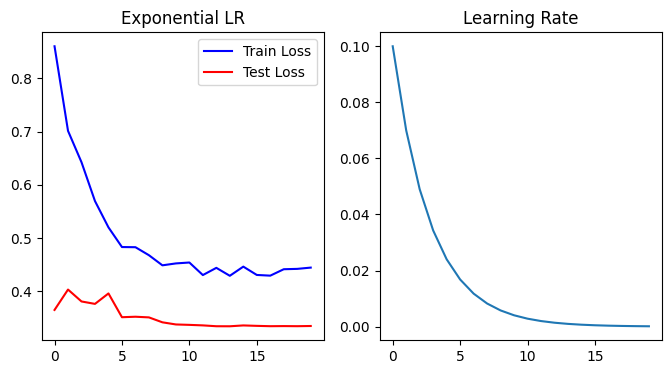

In [58]:
model_3 = DropoutModel().to(device).apply(initialize)
optimizer = Adam(model_3.parameters(), lr = 1e-1)
scheduler = ExponentialLR(optimizer, gamma=0.7)
loss_function = nn.CrossEntropyLoss()
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('Exponential LR')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()

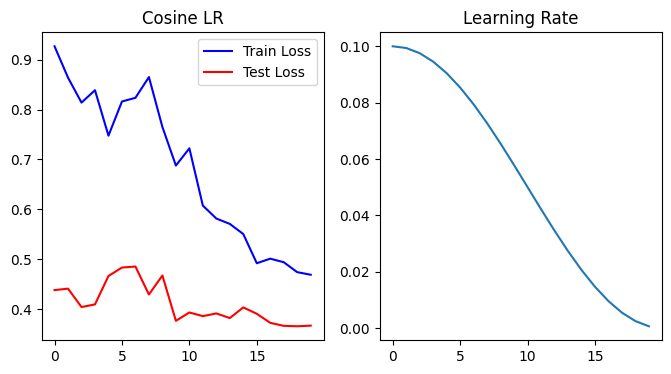

In [61]:
model_3 = DropoutModel().to(device).apply(initialize)
optimizer = Adam(model_3.parameters(), lr = 1e-1)
scheduler = CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-4)
loss_function = nn.CrossEntropyLoss()
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('Cosine LR')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()

In [63]:
def train_model(model, train_loader, test_loader,
                optimizer, scheduler, loss_function, epochs):
  train_loss, test_loss = [], []
  lr_history = []
  acc_history = []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
      learning_rate = optimizer.param_groups[0]['lr']
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))
    lr_history.append(learning_rate)
    accuracy = get_accuracy(model, X_test, y_test)
    acc_history.append(accuracy)

    scheduler.step(accuracy)
  return train_loss, test_loss, lr_history, acc_history


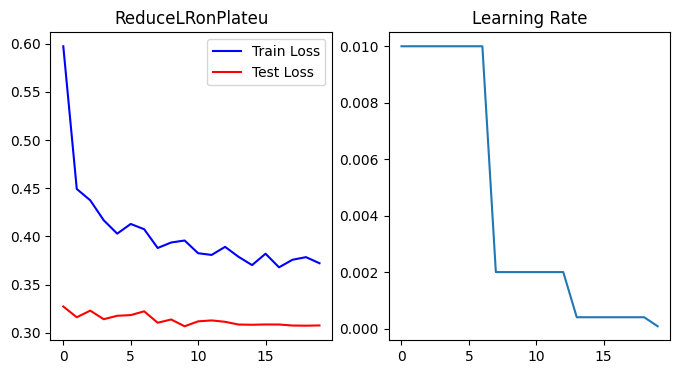

In [66]:
model_3 = DropoutModel().to(device).apply(initialize)
optimizer = AdamW(model_3.parameters(), lr = 1e-2, weight_decay=0.02)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=5)
loss_function = nn.CrossEntropyLoss()
train_loss_3, test_loss_3, lr_history, acc_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('ReduceLRonPlateu')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()

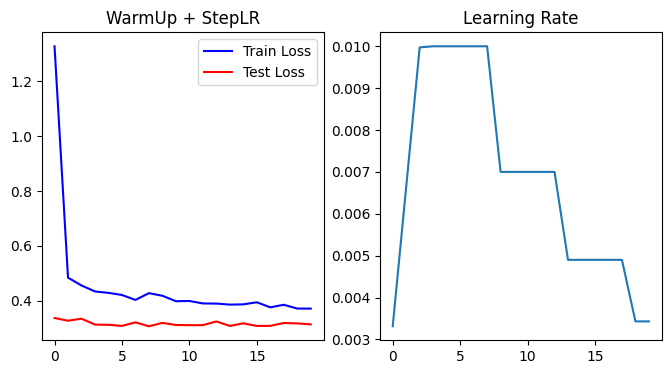

In [72]:
def train_model(model, train_loader, test_loader,
                optimizer, scheduler, warmup, loss_function, epochs):
  train_loss, test_loss = [], []
  lr_history = []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
      learning_rate = optimizer.param_groups[0]['lr']
      warmup.step()
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))

    if epoch >= 3:
      scheduler.step()
    lr_history.append(learning_rate)
  return train_loss, test_loss, lr_history

model_3 = DropoutModel().to(device).apply(initialize)
optimizer = AdamW(model_3.parameters(), lr = 1e-2, weight_decay=0.02)
scheduler = StepLR(optimizer, step_size=5, gamma=0.7)
warmup = LinearLR(optimizer, start_factor=0.001, end_factor=1, total_iters=3*len(train_loader))
loss_function = nn.CrossEntropyLoss()
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, warmup, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('WarmUp + StepLR')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()


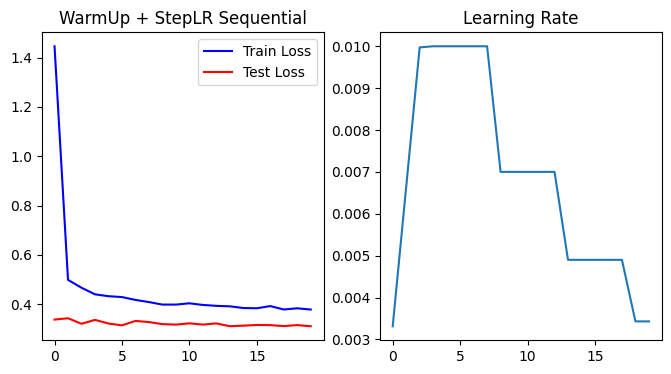

In [76]:
def train_model(model, train_loader, test_loader,
                optimizer, scheduler, loss_function, epochs):
  train_loss, test_loss = [], []
  lr_history = []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
      learning_rate = optimizer.param_groups[0]['lr']
      scheduler.step()
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))
    lr_history.append(learning_rate)
  return train_loss, test_loss, lr_history

model_3 = DropoutModel().to(device).apply(initialize)
optimizer = AdamW(model_3.parameters(), lr = 1e-2, weight_decay=0.02)
steps = len(train_loader)
warmup = LinearLR(optimizer, start_factor=0.001, end_factor=1.0, total_iters=3 * steps)
decay  = StepLR(optimizer, step_size=5 * steps, gamma=0.7)
scheduler = SequentialLR(optimizer, [warmup, decay], milestones=[3 * steps])
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('WarmUp + StepLR Sequential')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()


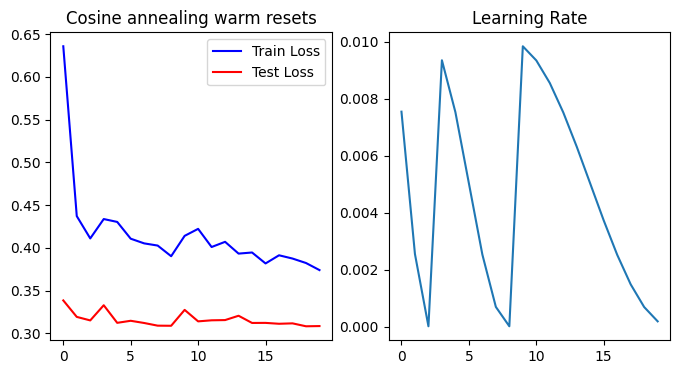

In [79]:
def train_model(model, train_loader, test_loader,
                optimizer, scheduler, loss_function, epochs):
  train_loss, test_loss = [], []
  lr_history = []
  for epoch in range(epochs):
    model.train()
    epoch_train_loss, epoch_test_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train, y_train = X_train.to(device), y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 1.0)
      optimizer.step()
      epoch_train_loss += loss.item()
      learning_rate = optimizer.param_groups[0]['lr']
      scheduler.step()
    train_loss.append(epoch_train_loss / len(train_loader))

    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        epoch_test_loss += loss_function(model(X_test), y_test).item()
    test_loss.append(epoch_test_loss / len(test_loader))
    lr_history.append(learning_rate)
  return train_loss, test_loss, lr_history

model_3 = DropoutModel().to(device).apply(initialize)
optimizer = AdamW(model_3.parameters(), lr = 1e-2, weight_decay=0.02)
n = len(train_loader)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=3 * n, T_mult=2, eta_min=1e-5)
train_loss_3, test_loss_3, lr_history = train_model(model_3, train_loader, test_loader, optimizer, scheduler, loss_function, 20)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(train_loss_3, label='Train Loss', color='blue')
ax[0].plot(test_loss_3, label='Test Loss', color='red')
ax[0].set_title('Cosine annealing warm resets')
ax[0].legend()
ax[1].plot(lr_history)
ax[1].set_title('Learning Rate')
plt.show()
